<a href="https://colab.research.google.com/github/ryouy/GraduationThesis/blob/main/1019/concept_specificity_control_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1019 v3 — X/Y 対照実験：抑制された概念の層別表現は本当に特異的か？

**Research question:** Does suppressing concept X affect the internal response specifically to X-related cues rather than Y-related or unrelated cues? Does the finding replicate when suppression target is **reversed from X to Y**?

This study is a targeted follow-up to the exploratory 1019 v2. It runs **8 X/Y concept pairs × 2 instructed targets (X or Y) × 2 conditions (permissive / suppression) × 3 independent, triplet-matched cue types (X / Y / unrelated) × 3 triplets** = 288 matched user prompts. Qwen2.5-0.5B-Instruct's **all 24 layers** are measured at two `STATE:` markers within the **same forward pass**, before and after the cue.

**Preselected focus:** layers **22, 23** (exploratory signals in v2), with layer 24 as a comparison and all 24 layers retained. No generative text is needed for the mechanistic question. Probe is trained separately using name + description contexts and tested on held-out name-free descriptions.

**Interpretation:** Probe X/Y score is *relative decodability*, NOT absolute concept activation, mental recall or a proved causal mechanism. Swapping the named target is a **controlled prompt manipulation**, not activation steering. Pre/post are different token positions within one causal input, not elapsed thinking time.

**Reproducibility:** Cue CSV and description bank are pinned to prior Git commits and saved with each run. CSV, charts, statistics and metadata go to `1019/results_v3/<UTC-run-id>/` locally and optionally to GitHub using Colab Secret `GITHUB_RESULTS_TOKEN`. No token is embedded in code or saved results.

## 0 — Environment, fixed settings, and prewritten controls

Select **Runtime → Change runtime type → T4 GPU**. Don't replace Colab's PyTorch/CUDA wheels.

In [1]:
%pip -q uninstall -y torchaudio torchvision
%pip -q install "transformers>=4.54,<5" "scikit-learn>=1.3" "scipy>=1.11" "pandas>=2.1" "matplotlib>=3.8" "tqdm>=4.65" "requests>=2.31"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 63.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 66.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
timm 1.0.30 requires torchvision, which is not installed.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, io, re, json, sys, random, zipfile, base64, hashlib, warnings
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import requests
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score

SEED=42
MODEL_ID="Qwen/Qwen2.5-0.5B-Instruct"
EMBED_ID="sentence-transformers/all-MiniLM-L6-v2"
MODEL_LAYERS=list(range(1,25))
MAIN_LAYER=24
FOCUS_LAYERS=[22,23]  # chosen BEFORE the v3 results, following v2 exploratory findings
AUC_CUTOFF=0.75
MIN_VALIDATED_FOR_LAYER_PLOT=5
CONDITIONS=["neutral","suppression"]
CUE_TYPES=["X","Y","unrelated"]
TARGET_ROLES=["X","Y"]
N_BOOT=5000
UPLOAD_TO_GITHUB=True
REPO="ryouy/GraduationThesis"
BRANCH="main"
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
DTYPE=torch.float16 if DEVICE=="cuda" else torch.float32
if DEVICE!="cuda":warnings.warn("Select the Colab T4 GPU runtime for much faster execution.")
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
ROOT=Path("/content/GraduationThesis") if Path("/content").exists() else Path.cwd()/"GraduationThesis"
OUT=ROOT/"1019"/"results_v3"/RUN_ID
OUT.mkdir(parents=True,exist_ok=True)
def save_csv(df,name):
    df.to_csv(OUT/name,index=False);print(f"Saved {name}: {len(df)} rows")
def save_figure(name):
    plt.tight_layout();plt.savefig(OUT/name,dpi=180,bbox_inches="tight");plt.show();plt.close()
def load_bytes(url):
    r=requests.get(url,timeout=60)
    r.raise_for_status()
    return r.content
STIMULI_URL=("https://raw.githubusercontent.com/ryouy/GraduationThesis/"
    "c0a375e0e7d65fbb1f67e80f05d5207d515186c0/1019/specificity_cues_v3.csv")
DESCRIPTION_URL=("https://raw.githubusercontent.com/ryouy/GraduationThesis/"
    "a6e058ed05c5a43e28cf46bdecd10eb54edcf19d/1019/probe_description_bank_v2.json")
stimulus_bytes=load_bytes(STIMULI_URL)
description_bytes=load_bytes(DESCRIPTION_URL)
cues=pd.read_csv(io.BytesIO(stimulus_bytes))
desc=json.loads(description_bytes.decode("utf-8"))
CONCEPTS=sorted(cues.concept.unique().tolist())
assert len(CONCEPTS)==8 and len(cues)==72
assert set(CONCEPTS)==set(desc)
assert cues.groupby(["concept","triplet"]).size().eq(3).all()
assert cues.groupby(["concept","cue_type"]).size().eq(3).all()
assert set(cues.cue_type)==set(CUE_TYPES)
def contains_word(s,w):
    return bool(re.search(r"(?<![A-Za-z])"+re.escape(w)+r"(?![A-Za-z])",s,re.I))
for item in cues.itertuples():
    assert not contains_word(item.cue_text,item.concept)
    assert not contains_word(item.cue_text,item.comparison)
    assert pd.notna(item.cue_text)
for x,d in desc.items():
    y=cues.loc[cues.concept==x,"comparison"].iloc[0]
    for split in ["x_train","x_test","y_train","y_test"]:
        assert len(d[split])==3
        assert all(not contains_word(s,x) and not contains_word(s,y) for s in d[split])
(OUT/"specificity_cues_v3.csv").write_bytes(stimulus_bytes)
(OUT/"probe_description_bank_v2.json").write_bytes(description_bytes)
INPUT_SHA256={"specificity_cues_v3":hashlib.sha256(stimulus_bytes).hexdigest(),
              "probe_description_bank_v2":hashlib.sha256(description_bytes).hexdigest()}
print("Validated",len(cues),"cue sentences for",len(CONCEPTS),"concept pairs")
display(cues.head(9))
print("Results:",OUT)

Validated 72 cue sentences for 8 concept pairs


,concept,comparison,triplet,cue_type,cue_text
0,banana,apple,1,X,A shopper noticed a long curved yellow fruit o...
1,banana,apple,1,Y,A shopper noticed a round crisp red fruit on t...
2,banana,apple,1,unrelated,A shopper noticed a metal kitchen timer on the...
3,banana,apple,2,X,A child ate a soft tropical fruit after peelin...
4,banana,apple,2,Y,A child ate a firm orchard fruit after slicing...
5,banana,apple,2,unrelated,A child used a blue measuring tape beside a desk.
6,banana,apple,3,X,A recipe featured a sweet elongated yellow pro...
7,banana,apple,3,Y,A recipe featured a tart round red produce item.
8,banana,apple,3,unrelated,A recipe featured an empty ceramic bowl on the...


Results: /content/GraduationThesis/1019/results_v3/20261020T070234997011Z


## 1 — Readout: the identical token position role across instructions and cues

The two `STATE:` markers occur *within* the user message. A single causal forward pass allows two readings at different positions. The pre-cue marker cannot read future tokens. By keeping the same prefix within each named target and condition, we can check that pre-cue states are invariant to cue wording.

In [3]:
tok=AutoTokenizer.from_pretrained(MODEL_ID,trust_remote_code=False,use_fast=True)
assert tok.is_fast,"Precise offset-mapped measurement requires a fast tokenizer."
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,dtype=DTYPE,
    low_cpu_mem_usage=True,trust_remote_code=False).to(DEVICE).eval()
assert model.config.num_hidden_layers==24
MARKER="STATE:"
def user_render(text):
    return tok.apply_chat_template([{"role":"user","content":text}],
        tokenize=False,add_generation_prompt=False)
@torch.inference_mode()
def state_readouts(user_text,expected_markers=1):
    rendered=user_render(user_text)
    occurrences=[m.span() for m in re.finditer(re.escape(MARKER),rendered)]
    if len(occurrences)!=expected_markers:
        raise ValueError(f"Expected {expected_markers} marker(s); saw {len(occurrences)}.")
    batch=tok(rendered,return_offsets_mapping=True,add_special_tokens=False,
        return_tensors="pt")
    offsets=batch.pop("offset_mapping")[0].tolist()
    ids=batch["input_ids"][0].tolist()
    positions=[]
    for start,end in occurrences:
        hits=[i for i,(lo,hi) in enumerate(offsets) if lo<=end-1<hi]
        if len(hits)!=1:raise ValueError(f"Cannot locate terminal marker token: {start,end,hits}")
        positions.append(hits[0])
    if len(set(ids[i] for i in positions))!=1:
        raise ValueError("Marker token IDs differ between readouts; investigate tokenizer boundaries.")
    inp={k:v.to(DEVICE) for k,v in batch.items()}
    result=model(**inp,output_hidden_states=True,use_cache=False,return_dict=True)
    states=[]
    for token_pos in positions:
        states.append(np.stack([
            result.hidden_states[l][0,token_pos,:].float().cpu().numpy()
            for l in MODEL_LAYERS
        ],axis=0))
    # shape each (24,hidden_width), order 1..24; no hidden states saved on GitHub by default.
    return states,positions,len(ids)
demo,position,n_tokens=state_readouts(
    "You may think about banana. Continue reading.\nSTATE:\n"
    "A curved yellow fruit was peeled.\nSTATE:\n",expected_markers=2)
assert len(demo)==2 and all(np.isfinite(z).all() for z in demo)
assert position[0]<position[1]
print("Readout positions:",position,"of",n_tokens,"tokens; vectors:",demo[0].shape)
print("Each row corresponds to a transformer layer from 1 to 24.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Readout positions: [34, 43] of 46 tokens; vectors: (24, 896)
Each row corresponds to a transformer layer from 1 to 24.


## 2 — Independent concept-probe training and validation

Per concept pair and transformer layer, fit a regularized linear probe on named and name-free descriptions. Evaluate separately using **unseen description sentences**. Training/test description families still share semantic attributes (the classifier is not automatically a universally valid concept detector). Keep *all* probe measurements, mark held-out description AUC≥0.75 in output.

In [4]:
TRAIN_NAME_FRAMES=[
    "The concept is {}.\nSTATE:\n",
    "Focus attention on {}.\nSTATE:\n",
]
TRAIN_DESCRIPTION_FRAMES=[
    "A short definition is {}.\nSTATE:\n",
    "The subject is described as {}.\nSTATE:\n",
]
TEST_DESCRIPTION_FRAMES=[
    "A curator wrote about {}.\nSTATE:\n",
    "An observer reported {}.\nSTATE:\n",
]
TEST_NAME_FRAMES=["The discussion concerns {}.\nSTATE:\n"]

probe_examples=[]
for x in tqdm(CONCEPTS,desc="Construct independent concept probes"):
    y=cues.loc[cues.concept==x,"comparison"].iloc[0]
    bank=desc[x]
    for label,word,prefix in [(1,x,"x"),(0,y,"y")]:
        for frame in TRAIN_NAME_FRAMES:
            prompt=frame.format(word)
            h,_,_=state_readouts(prompt,1)
            probe_examples.append(dict(concept=x,split="train",y=label,prompt=prompt,feature=h[0]))
        for phrase in bank[f"{prefix}_train"]:
            for frame in TRAIN_DESCRIPTION_FRAMES:
                prompt=frame.format(phrase)
                h,_,_=state_readouts(prompt,1)
                probe_examples.append(dict(concept=x,split="train",y=label,prompt=prompt,feature=h[0]))
        for phrase in bank[f"{prefix}_test"]:
            for frame in TEST_DESCRIPTION_FRAMES:
                prompt=frame.format(phrase)
                h,_,_=state_readouts(prompt,1)
                probe_examples.append(dict(concept=x,split="holdout_description",y=label,
                                           prompt=prompt,feature=h[0]))
        for frame in TEST_NAME_FRAMES:
            prompt=frame.format(word)
            h,_,_=state_readouts(prompt,1)
            probe_examples.append(dict(concept=x,split="holdout_named",y=label,
                                       prompt=prompt,feature=h[0]))
probe_data=pd.DataFrame(probe_examples)
assert probe_data.groupby(["concept","split"]).size().unstack().loc[
    :,["train","holdout_description","holdout_named"]].eq([16,12,2]).all().all()
probes={};metrics=[]
for x in CONCEPTS:
    train=probe_data[(probe_data.concept==x)&(probe_data.split=="train")]
    probes[x]={}
    for layer in MODEL_LAYERS:
        ix=layer-1
        X=np.stack([v[ix] for v in train.feature])
        y=train.y.to_numpy()
        clf=make_pipeline(StandardScaler(),
            LogisticRegression(C=0.1,solver="liblinear",random_state=SEED,max_iter=2500))
        clf.fit(X,y)
        decision_sd=max(float(np.std(clf.decision_function(X),ddof=1)),1e-8)
        probes[x][layer]=(clf,decision_sd)
        for split in ["holdout_description","holdout_named"]:
            ev=probe_data[(probe_data.concept==x)&(probe_data.split==split)]
            held=np.stack([v[ix] for v in ev.feature])
            raw=clf.decision_function(held)
            gt=ev.y.to_numpy()
            metrics.append(dict(concept=x,layer=layer,split=split,n=len(gt),
                auc=float(roc_auc_score(gt,raw)),
                accuracy=float(accuracy_score(gt,raw>=0)),
                train_decision_sd=decision_sd))
all_validation=pd.DataFrame(metrics)
validation=all_validation[all_validation.split=="holdout_description"].copy()
validation["valid_probe"]=validation.auc>=AUC_CUTOFF
save_csv(all_validation,"03_probe_validation_all_layers.csv")
save_csv(validation,"04_probe_validation_flags.csv")
counts=validation.groupby("layer",as_index=False).agg(
    n_passed=("valid_probe","sum"),mean_auc=("auc","mean"),
    mean_accuracy=("accuracy","mean"))
save_csv(counts,"05_probe_validation_per_layer.csv")
display(counts.round(3))
print("Final layer valid:",counts.loc[counts.layer==MAIN_LAYER,"n_passed"].iloc[0],"/8")
del probe_data,probe_examples
if torch.cuda.is_available():torch.cuda.empty_cache()

Construct independent concept probes:   0%|          | 0/8 [00:00<?, ?it/s]

Saved 03_probe_validation_all_layers.csv: 384 rows
Saved 04_probe_validation_flags.csv: 192 rows
Saved 05_probe_validation_per_layer.csv: 24 rows


,layer,n_passed,mean_auc,mean_accuracy
0,1,6,0.854,0.781
1,2,7,0.885,0.740
2,3,7,0.896,0.750
3,4,6,0.875,0.677
4,5,7,0.913,0.677
5,6,7,0.868,0.688
6,7,8,0.892,0.688
7,8,7,0.851,0.698
8,9,6,0.819,0.656
9,10,6,0.799,0.635


Final layer valid: 8 /8


## 3 — Independent semantic audit and token-length balance

The **X/Y/U cue set was written before observing v3 outputs**. MiniLM independently checks whether X-related cues are closer to X, Y-related cues to Y, and unrelated cues reasonably distant from both. This audit is descriptive; imperfect ordering is preserved rather than silently filtering stimuli. Qwen token-length differences are also recorded.

In [5]:
encoder_tok=AutoTokenizer.from_pretrained(EMBED_ID,trust_remote_code=False)
encoder=AutoModel.from_pretrained(EMBED_ID,trust_remote_code=False).cpu().eval()
anchors=[]
for x in CONCEPTS:
    y=cues.loc[cues.concept==x,"comparison"].iloc[0]
    anchors.extend([f"This text concerns {x}.",f"This text concerns {y}."])
texts=anchors+cues.cue_text.tolist()
vectors=[]
for start in tqdm(range(0,len(texts),32),desc="Independent MiniLM similarity audit"):
    batch=encoder_tok(texts[start:start+32],return_tensors="pt",
                      padding=True,truncation=True,max_length=128)
    with torch.inference_mode():
        h=encoder(**batch).last_hidden_state
        mask=batch.attention_mask.unsqueeze(-1)
        v=(h*mask).sum(1)/mask.sum(1).clamp(min=1)
        vectors.append(F.normalize(v.float(),p=2,dim=1).cpu().numpy())
vectors=np.concatenate(vectors,axis=0)
anchor_vectors={}
for idx,x in enumerate(CONCEPTS):
    anchor_vectors[x]=(vectors[2*idx],vectors[2*idx+1])
cues=cues.reset_index(drop=True)
cues["sim_X"]=[float(anchor_vectors[r.concept][0]@vectors[2*len(CONCEPTS)+i])
               for i,r in cues.iterrows()]
cues["sim_Y"]=[float(anchor_vectors[r.concept][1]@vectors[2*len(CONCEPTS)+i])
               for i,r in cues.iterrows()]
cues["X_minus_Y_similarity"]=cues.sim_X-cues.sim_Y
cues["independent_expected_direction"]=np.where(cues.cue_type=="X",
   cues.X_minus_Y_similarity>0,
   np.where(cues.cue_type=="Y",cues.X_minus_Y_similarity<0,True))
cues["cue_token_count"]=cues.cue_text.apply(lambda text:
    len(tok(text,add_special_tokens=False).input_ids))
save_csv(cues,"01_audited_XY_control_stimuli.csv")
audit=cues.groupby(["concept","cue_type"],as_index=False).agg(
    mean_preference=("X_minus_Y_similarity","mean"),
    mean_token_count=("cue_token_count","mean"),
    direction_passes=("independent_expected_direction","sum"),
    n=("cue_text","size"))
save_csv(audit,"02_embedding_and_length_audit.csv")
display(audit.pivot(index="concept",columns="cue_type",values="mean_preference").round(3))
print("X/Y cue-direction checks passed:",
      int(cues[cues.cue_type.isin(["X","Y"])].independent_expected_direction.sum()),
      "/",len(cues[cues.cue_type.isin(["X","Y"])]))
del encoder,encoder_tok,vectors
if torch.cuda.is_available():torch.cuda.empty_cache()

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Independent MiniLM similarity audit:   0%|          | 0/3 [00:00<?, ?it/s]

Saved 01_audited_XY_control_stimuli.csv: 72 rows
Saved 02_embedding_and_length_audit.csv: 24 rows


cue_type,X,Y,unrelated
concept,,,
banana,0.187,0.164,0.047
bicycle,0.044,-0.042,0.023
castle,0.081,-0.120,-0.048
coffee,0.193,-0.073,0.036
elephant,0.001,-0.007,-0.010
ocean,0.202,-0.115,-0.033
piano,0.196,-0.094,0.089
tiger,0.028,-0.032,-0.038


X/Y cue-direction checks passed: 39 / 48


## 4 — Main experiment: swap forbidden target, keep cue triplet unchanged

For each pair (X,Y), run instruction about **X and then Y**, and both `neutral`/`suppression` conditions. Each wording explicitly names the current target **once**. All three cue types and all three prewritten matched triplets are used without filtering. Probe scores are expressed in X/Y units, then **sign-flipped for target=Y**, so positive means *toward the currently named target* in either direction. Pre/post state readouts and full hidden-state displacement are retained for all 24 layers.

In [6]:
def instruction(target,condition):
    return {
      "neutral":f"You may think about {target}. Continue reading.",
      "suppression":f"Do not think about {target}. Continue reading."
    }[condition]
def experiment_prompt(target,condition,cue):
    return instruction(target,condition)+"\nSTATE:\n"+cue+"\nSTATE:\n"
probe_lookup={(row.concept,int(row.layer)):(float(row.auc),bool(row.valid_probe))
              for row in validation.itertuples()}
results=[]
invariance={}
for x in tqdm(CONCEPTS,desc="V3: 288 controlled contexts, 24 layers"):
    y=cues.loc[cues.concept==x,"comparison"].iloc[0]
    sub=cues[cues.concept==x]
    for target_role,target,sign in [("X",x,1),("Y",y,-1)]:
        for cond in CONDITIONS:
            pre_reference=None
            maximum=0.0
            for row in sub.itertuples():
                p=experiment_prompt(target,cond,row.cue_text)
                (pre,post),positions,n_tokens=state_readouts(p,expected_markers=2)
                if pre_reference is None:pre_reference=pre.copy()
                else:maximum=max(maximum,float(np.max(np.abs(pre_reference-pre))))
                cue_role=("target" if row.cue_type==target_role else
                          "unrelated" if row.cue_type=="unrelated" else "other")
                for layer in MODEL_LAYERS:
                    clf,sd=probes[x][layer]
                    raw_pre=float(clf.decision_function(pre[layer-1].reshape(1,-1))[0])
                    raw_post=float(clf.decision_function(post[layer-1].reshape(1,-1))[0])
                    u=pre[layer-1].astype(np.float64)
                    v=post[layer-1].astype(np.float64)
                    cos=float(u@v/max(np.linalg.norm(u)*np.linalg.norm(v),1e-12))
                    auc,passed=probe_lookup[(x,layer)]
                    results.append(dict(
                        concept=x,comparison=y,target_role=target_role,target=target,
                        target_orientation=sign,condition=cond,triplet=row.triplet,
                        cue_type=row.cue_type,cue_role=cue_role,cue_text=row.cue_text,
                        sim_X=row.sim_X,sim_Y=row.sim_Y,
                        cue_token_count=row.cue_token_count,
                        prompt_tokens=n_tokens,pre_pos=positions[0],post_pos=positions[1],
                        layer=layer,probe_auc=auc,validated=passed,
                        pre_XY_std=raw_pre/sd,post_XY_std=raw_post/sd,
                        pre_target_std=sign*raw_pre/sd,
                        post_target_std=sign*raw_post/sd,
                        delta_target_std=sign*(raw_post-raw_pre)/sd,
                        hidden_cosine_distance=1-cos,
                        hidden_relative_L2=float(np.linalg.norm(v-u)/max(np.linalg.norm(u),1e-12)),
                        prompt=p))
            invariance[x+"_"+target_role+"_"+cond]=maximum
measure=pd.DataFrame(results)
assert len(measure)==8*2*2*3*3*24
assert not measure[["pre_target_std","post_target_std","delta_target_std"]].isna().any().any()
save_csv(measure,"03_all_layer_target_aligned_pre_post.csv")
inv_df=pd.DataFrame([dict(context=k,max_abs_difference=v) for k,v in invariance.items()])
save_csv(inv_df,"04_precue_causal_invariance.csv")
print("Maximum pre-cue difference:",max(invariance.values()))
assert max(invariance.values())<0.01,"Unexpected cue dependence BEFORE cue. Inspect tokenizer/causal mask."
length_diag=measure[measure.layer==24].groupby(
 ["target_role","condition","cue_role"],as_index=False).agg(
  mean_cue_tokens=("cue_token_count","mean"),
  mean_prompt_tokens=("prompt_tokens","mean"),
  min_prompt_tokens=("prompt_tokens","min"),max_prompt_tokens=("prompt_tokens","max"))
save_csv(length_diag,"05_prompt_and_cue_length_diagnostics.csv")
display(length_diag)

V3: 288 controlled contexts, 24 layers:   0%|          | 0/8 [00:00<?, ?it/s]

Saved 03_all_layer_target_aligned_pre_post.csv: 6912 rows
Saved 04_precue_causal_invariance.csv: 32 rows
Maximum pre-cue difference: 0.0
Saved 05_prompt_and_cue_length_diagnostics.csv: 12 rows


,target_role,condition,cue_role,mean_cue_tokens,mean_prompt_tokens,min_prompt_tokens,max_prompt_tokens
0,X,neutral,other,11.708333,50.708333,49,53
1,X,neutral,target,11.875000,50.875000,49,53
2,X,neutral,unrelated,10.875000,49.875000,49,51
3,X,suppression,other,11.708333,50.708333,49,53
4,X,suppression,target,11.875000,50.875000,49,53
5,X,suppression,unrelated,10.875000,49.875000,49,51
6,Y,neutral,other,11.875000,51.000000,49,54
7,Y,neutral,target,11.708333,50.833333,49,53
8,Y,neutral,unrelated,10.875000,50.000000,49,51
9,Y,suppression,other,11.875000,51.000000,49,54


## 5 — Core paired contrasts: concept specificity versus generic response

For each matched triplet and layer, calculate `Δ = Probe(after) − Probe(before)` in **target-aligned standardized X/Y units**. The primary specificity contrast is:

- `C_neutral = Δ(neutral, target-cue) − Δ(neutral, other-cue)`
- `C_suppression = Δ(suppression, target-cue) − Δ(suppression, other-cue)`
- **`Specificity interaction = C_suppression − C_neutral`** (primary).

Secondary control: subtract the unrelated cue instead of the other-target cue. A positive value means the targeted-versus-competing-cue contrast is greater under suppression, **not** that suppression makes the target absolutely more active. All results are retained, including cases where the direction reverses.

In [7]:
key=["concept","comparison","target_role","target","target_orientation",
     "triplet","cue_type","cue_role","cue_text","cue_token_count",
     "layer","validated","probe_auc"]
paired=measure.pivot(index=key,columns="condition",
    values=["delta_target_std","pre_target_std","post_target_std","hidden_cosine_distance"]).reset_index()
paired.columns=["_".join(map(str,part)) if isinstance(part,tuple) and part[1] else
                part[0] if isinstance(part,tuple) else part for part in paired.columns]
paired["suppression_minus_neutral_delta"]=(
    paired.delta_target_std_suppression-paired.delta_target_std_neutral)
save_csv(paired,"06_paired_instruction_contrasts.csv")

rolekeys=["concept","comparison","target_role","triplet","layer","validated","probe_auc"]
rolewide=paired.pivot(index=rolekeys,columns="cue_role",
    values=["delta_target_std_neutral","delta_target_std_suppression",
            "suppression_minus_neutral_delta","cue_token_count"]).reset_index()
rolewide.columns=["_".join(map(str,part)) if isinstance(part,tuple) and part[1] else
                   part[0] if isinstance(part,tuple) else part for part in rolewide.columns]
assert len(rolewide)==8*2*3*24
assert not rolewide.filter(like="delta_target_std").isna().any().any()
rolewide["neutral_specificity"]=(
    rolewide.delta_target_std_neutral_target-rolewide.delta_target_std_neutral_other)
rolewide["suppression_specificity"]=(
    rolewide.delta_target_std_suppression_target-rolewide.delta_target_std_suppression_other)
rolewide["specificity_interaction"]=(
    rolewide.suppression_specificity-rolewide.neutral_specificity)
rolewide["DID_target_vs_unrelated"]=(
    rolewide.suppression_minus_neutral_delta_target-
    rolewide.suppression_minus_neutral_delta_unrelated)
rolewide["DID_other_vs_unrelated"]=(
    rolewide.suppression_minus_neutral_delta_other-
    rolewide.suppression_minus_neutral_delta_unrelated)
rolewide["target_minus_other_token_count"]=(
    rolewide.cue_token_count_target-rolewide.cue_token_count_other)
rolewide["target_minus_unrelated_token_count"]=(
    rolewide.cue_token_count_target-rolewide.cue_token_count_unrelated)
save_csv(rolewide,"07_triplet_matched_specificity.csv")

by_role=rolewide.groupby(["concept","comparison","target_role","layer","validated"],as_index=False).agg(
    neutral_specificity=("neutral_specificity","mean"),
    suppression_specificity=("suppression_specificity","mean"),
    specificity_interaction=("specificity_interaction","mean"),
    DID_target_vs_unrelated=("DID_target_vs_unrelated","mean"),
    DID_other_vs_unrelated=("DID_other_vs_unrelated","mean"),
    mean_token_difference_target_other=("target_minus_other_token_count","mean"),
    n_triplets=("triplet","size"))
save_csv(by_role,"08_specificity_by_concept_target_layer.csv")
by_concept=by_role.groupby(["concept","layer","validated"],as_index=False).agg(
    neutral_specificity=("neutral_specificity","mean"),
    suppression_specificity=("suppression_specificity","mean"),
    specificity_interaction=("specificity_interaction","mean"),
    DID_target_vs_unrelated=("DID_target_vs_unrelated","mean"),
    DID_other_vs_unrelated=("DID_other_vs_unrelated","mean"),
    n_target_roles=("target_role","nunique"))
assert by_concept.n_target_roles.eq(2).all()
save_csv(by_concept,"09_specificity_by_concept_layer.csv")
display(by_role[by_role.layer.isin(FOCUS_LAYERS+[MAIN_LAYER])][
    ["concept","target_role","layer","validated","neutral_specificity",
     "suppression_specificity","specificity_interaction"]].round(3))

Saved 06_paired_instruction_contrasts.csv: 3456 rows
Saved 07_triplet_matched_specificity.csv: 1152 rows
Saved 08_specificity_by_concept_target_layer.csv: 384 rows
Saved 09_specificity_by_concept_layer.csv: 192 rows


,concept,target_role,layer,validated,neutral_specificity,suppression_specificity,specificity_interaction
21,banana,X,22,True,0.384,0.223,-0.161
22,banana,X,23,True,0.463,0.281,-0.182
23,banana,X,24,True,0.443,0.301,-0.142
45,banana,Y,22,True,0.371,0.266,-0.105
46,banana,Y,23,True,0.481,0.340,-0.141
47,banana,Y,24,True,0.420,0.324,-0.096
69,bicycle,X,22,True,0.647,0.547,-0.100
70,bicycle,X,23,True,0.713,0.603,-0.110
71,bicycle,X,24,True,0.622,0.554,-0.068
93,bicycle,Y,22,True,0.716,0.645,-0.071


## 6 — Cluster-aware uncertainty and a prespecified layer-22/23 average

The **independent analysis unit is the concept pair** (8 X/Y pairs), not 288 prompts, 3 paraphrases, or 2 target-role swaps. Average the 3 matched triplets and 2 reversed targets *within concept*, then bootstrap 8 concept pairs. Because v2 motivated layers 22–23, this is a **follow-up exploratory check**, not independent confirmatory preregistration. Show all 24 layers and the target-swap breakdown, including conflicting directions.

In [8]:
def bootstrap_concept_effect(values,n_boot=N_BOOT,seed=SEED):
    values=np.asarray(values,dtype=float)
    values=values[np.isfinite(values)]
    if len(values)<3:
        return float(values.mean()) if len(values) else np.nan,np.nan,np.nan
    rng=np.random.default_rng(seed)
    sims=rng.choice(values,(n_boot,len(values)),replace=True).mean(axis=1)
    return float(values.mean()),float(np.quantile(sims,.025)),float(np.quantile(sims,.975))

KEY_OUTCOMES=["specificity_interaction","DID_target_vs_unrelated","neutral_specificity",
              "suppression_specificity"]
summaries=[]
for layer in MODEL_LAYERS:
    for mode in ["all","validated"]:
        q=by_concept[by_concept.layer==layer]
        if mode=="validated":q=q[q.validated]
        for outcome in KEY_OUTCOMES:
            m,lo,hi=bootstrap_concept_effect(q[outcome].values,
                seed=SEED+layer*23+KEY_OUTCOMES.index(outcome)*7+(1000 if mode=="validated" else 0))
            summaries.append(dict(layer=layer,analysis=mode,metric=outcome,
                n_concept_pairs=len(q),estimate=m,ci95_low=lo,ci95_high=hi,
                n_positive=int((q[outcome]>0).sum()),n_negative=int((q[outcome]<0).sum())))
summary_df=pd.DataFrame(summaries)
save_csv(summary_df,"10_layerwise_concept_bootstrap.csv")

# Preselected exploratory focus: 22/23 averaged within each concept first.
focus=by_concept[by_concept.layer.isin(FOCUS_LAYERS)].groupby("concept",as_index=False).agg(
    focus_specificity_interaction=("specificity_interaction","mean"),
    focus_neutral_specificity=("neutral_specificity","mean"),
    focus_suppression_specificity=("suppression_specificity","mean"),
    focus_DID_target_vs_unrelated=("DID_target_vs_unrelated","mean"),
    n_layers=("layer","nunique"))
assert focus.n_layers.eq(len(FOCUS_LAYERS)).all()
save_csv(focus,"11_prespecified_layers_22_23_by_concept.csv")
main_outcomes=[]
for column in ["focus_specificity_interaction","focus_neutral_specificity",
               "focus_suppression_specificity","focus_DID_target_vs_unrelated"]:
    m,lo,hi=bootstrap_concept_effect(focus[column].values,seed=SEED+len(column))
    main_outcomes.append(dict(metric=column,estimate=m,ci95_low=lo,ci95_high=hi,
        n_pairs=len(focus),n_positive=int((focus[column]>0).sum()),
        n_negative=int((focus[column]<0).sum())))
main_summary=pd.DataFrame(main_outcomes)
save_csv(main_summary,"12_prespecified_22_23_bootstrap.csv")
display(main_summary.round(4))
print("Interpret confidence intervals cautiously: 8 hand-selected concept pairs, exploratory.")
print("No result was used to select or exclude concept pairs beyond independent held-out AUC.")

Saved 10_layerwise_concept_bootstrap.csv: 192 rows
Saved 11_prespecified_layers_22_23_by_concept.csv: 8 rows
Saved 12_prespecified_22_23_bootstrap.csv: 4 rows


,metric,estimate,ci95_low,ci95_high,n_pairs,n_positive,n_negative
0,focus_specificity_interaction,-0.1102,-0.1355,-0.0780,8,0,8
1,focus_neutral_specificity,0.6903,0.5087,0.8632,8,8,0
2,focus_suppression_specificity,0.5802,0.4144,0.7290,8,8,0
3,focus_DID_target_vs_unrelated,-0.0659,-0.0874,-0.0456,8,0,8


Interpret confidence intervals cautiously: 8 hand-selected concept pairs, exploratory.
No result was used to select or exclude concept pairs beyond independent held-out AUC.


## 7 — Figures: validation, all-layer specificity, suppression interaction, reversed targets

Figures display **observed values only** after Colab execution. Main curves require a held-out description ROC-AUC≥0.75 and at least five valid concept probes at the respective layer. Individual concepts, both named-target directions, and uncertain findings are preserved rather than showing only favorable layers.

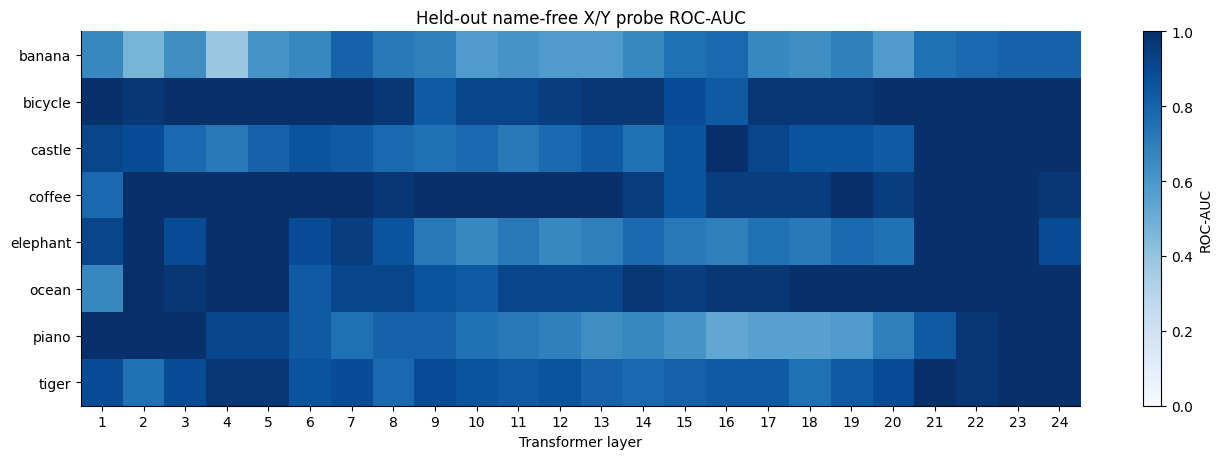

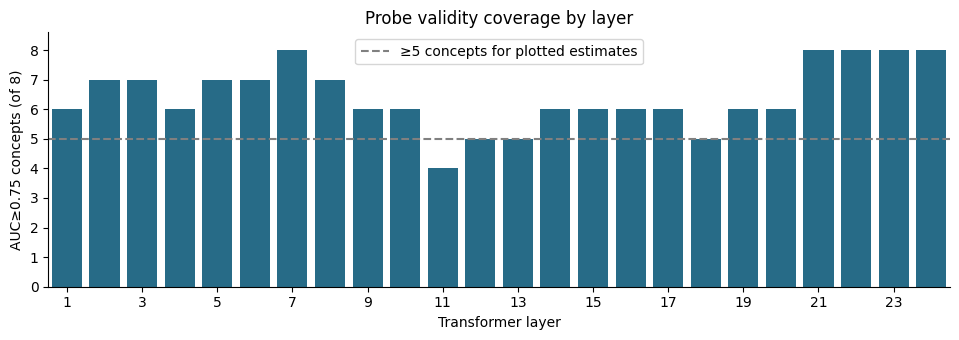

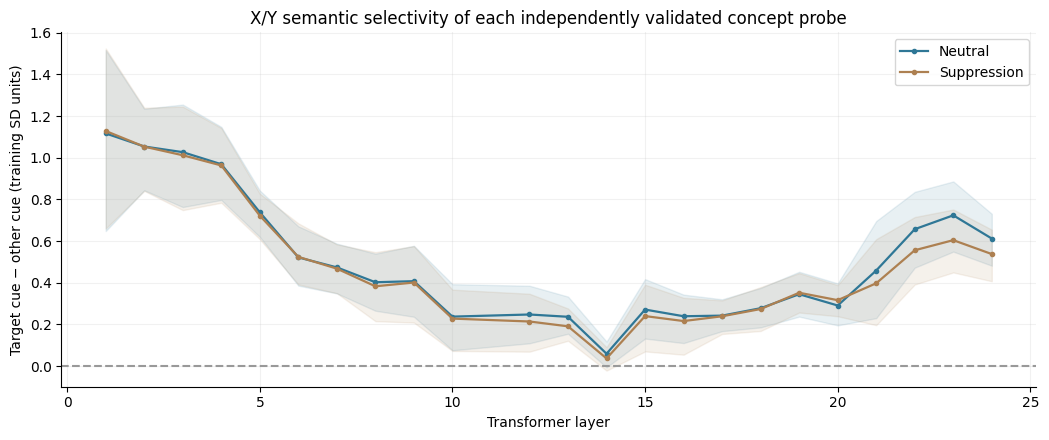

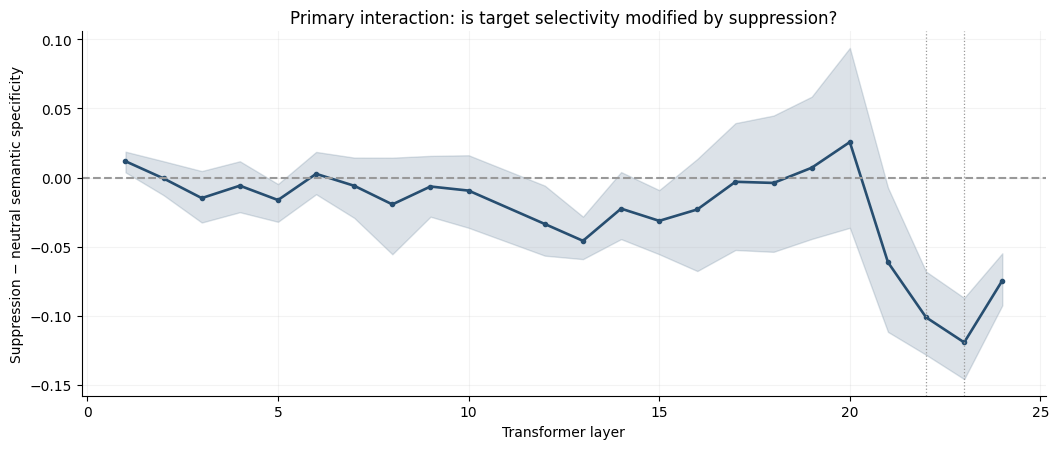

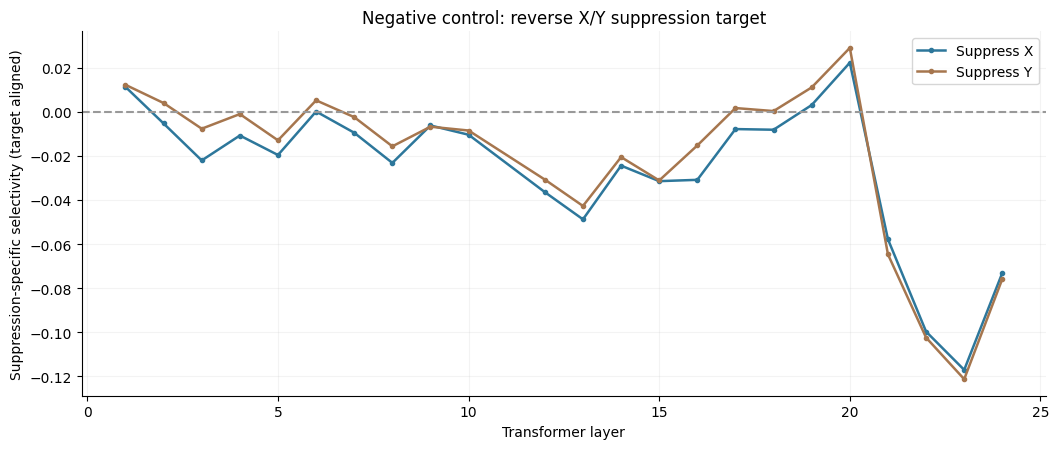

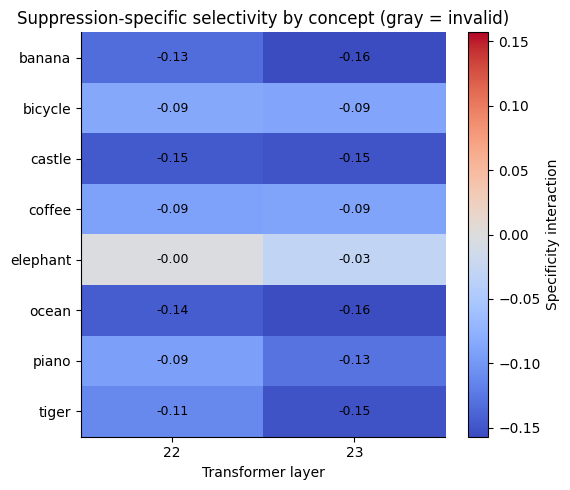

In [9]:
plt.rcParams.update({"font.size":10,"axes.spines.top":False,
 "axes.spines.right":False,"savefig.facecolor":"white"})
# Figure 1: held-out description AUC across all 24 layers
auc=validation.pivot(index="concept",columns="layer",values="auc").reindex(
    index=CONCEPTS,columns=MODEL_LAYERS)
fig,ax=plt.subplots(figsize=(13.5,4.7))
im=ax.imshow(auc.to_numpy(),cmap="Blues",vmin=0,vmax=1,aspect="auto")
ax.set(xticks=np.arange(24),xticklabels=MODEL_LAYERS,
       yticks=np.arange(len(CONCEPTS)),yticklabels=CONCEPTS,
       xlabel="Transformer layer",title="Held-out name-free X/Y probe ROC-AUC")
fig.colorbar(im,ax=ax,label="ROC-AUC")
save_figure("01_probe_AUC_all_24_layers.png")

# Figure 2: independently validated concept count by layer
fig,ax=plt.subplots(figsize=(9.7,3.5))
ax.bar(counts.layer,counts.n_passed,color="#276B87")
ax.axhline(MIN_VALIDATED_FOR_LAYER_PLOT,color="gray",ls="--",label="≥5 concepts for plotted estimates")
ax.set(xlim=(.5,24.5),ylim=(0,8.6),
       xlabel="Transformer layer",ylabel="AUC≥0.75 concepts (of 8)",
       title="Probe validity coverage by layer")
ax.set_xticks(list(range(1,25,2)));ax.legend()
save_figure("02_probe_validity_coverage.png")

# Figure 3: neutral/suppressed X-vs-Y specificity itself
fig,ax=plt.subplots(figsize=(10.6,4.5))
for col,color,label in [("neutral_specificity","#2F7796","Neutral"),
                          ("suppression_specificity","#AD8051","Suppression")]:
    q=summary_df[(summary_df.analysis=="validated")&(summary_df.metric==col)&
                 (summary_df.n_concept_pairs>=MIN_VALIDATED_FOR_LAYER_PLOT)].sort_values("layer")
    if len(q):
        ax.plot(q.layer,q.estimate,"-o",markersize=3,lw=1.6,color=color,label=label)
        ax.fill_between(q.layer.to_numpy(float),q.ci95_low.to_numpy(float),
            q.ci95_high.to_numpy(float),alpha=.11,color=color)
ax.axhline(0,color="0.6",ls="--")
ax.set(xlabel="Transformer layer",ylabel="Target cue − other cue (training SD units)",
       title="X/Y semantic selectivity of each independently validated concept probe")
ax.grid(alpha=.17);ax.legend()
save_figure("03_target_cue_vs_competitor_by_layer.png")

# Figure 4: primary suppression-specific change in semantic selectivity
q=summary_df[(summary_df.analysis=="validated")&
             (summary_df.metric=="specificity_interaction")&
             (summary_df.n_concept_pairs>=MIN_VALIDATED_FOR_LAYER_PLOT)].sort_values("layer")
fig,ax=plt.subplots(figsize=(10.7,4.6))
if len(q):
    ax.plot(q.layer,q.estimate,"-o",color="#274E70",markersize=3,lw=1.9)
    ax.fill_between(q.layer.to_numpy(float),q.ci95_low.to_numpy(float),
        q.ci95_high.to_numpy(float),color="#274E70",alpha=.16)
ax.axhline(0,color="0.6",ls="--")
for focus_layer in FOCUS_LAYERS:ax.axvline(focus_layer,color="#999999",ls=":",lw=.9)
ax.set(xlabel="Transformer layer",ylabel="Suppression − neutral semantic specificity",
       title="Primary interaction: is target selectivity modified by suppression?")
ax.grid(alpha=.14)
save_figure("04_suppression_specificity_interaction_all_layers.png")

# Figure 5: target reversal (X-suppression versus Y-suppression) as a counterbalance
fig,ax=plt.subplots(figsize=(10.7,4.6))
for target_role,color in [("X","#2D779B"),("Y","#A6764E")]:
    a=by_role[(by_role.target_role==target_role)&(by_role.validated)]
    means=a.groupby("layer").agg(value=("specificity_interaction","mean"),
                                 n=("concept","nunique")).reset_index()
    means=means[means.n>=MIN_VALIDATED_FOR_LAYER_PLOT]
    if len(means):
        ax.plot(means.layer,means.value,"-o",color=color,label="Suppress "+target_role,
                markersize=3,lw=1.8)
ax.axhline(0,color="0.6",ls="--")
ax.set(xlabel="Transformer layer",ylabel="Suppression-specific selectivity (target aligned)",
       title="Negative control: reverse X/Y suppression target")
ax.grid(alpha=.15)
if ax.get_legend_handles_labels()[1]:ax.legend()
save_figure("05_reversed_target_comparison.png")

# Figure 6: individual concept-pair outcomes in the focus layers
focused=by_concept[by_concept.layer.isin(FOCUS_LAYERS)]
grid=focused.pivot(index="concept",columns="layer",values="specificity_interaction").reindex(
    index=CONCEPTS,columns=FOCUS_LAYERS)
valid_grid=focused.pivot(index="concept",columns="layer",values="validated").reindex(
    index=CONCEPTS,columns=FOCUS_LAYERS).fillna(False).to_numpy(dtype=bool)
value=np.where(valid_grid,grid.to_numpy(float),np.nan)
finite=value[np.isfinite(value)]
scale=max(.1,float(np.quantile(np.abs(finite),.95))) if len(finite) else 1.0
color=plt.get_cmap("coolwarm").copy();color.set_bad("#E7E7E7")
fig,ax=plt.subplots(figsize=(5.8,5))
im=ax.imshow(np.ma.masked_invalid(value),cmap=color,vmin=-scale,vmax=scale,aspect="auto")
ax.set(xticks=[0,1],xticklabels=FOCUS_LAYERS,yticks=np.arange(len(CONCEPTS)),
       yticklabels=CONCEPTS,xlabel="Transformer layer",
       title="Suppression-specific selectivity by concept (gray = invalid)")
for i in range(len(CONCEPTS)):
    for j in range(len(FOCUS_LAYERS)):
        if np.isfinite(value[i,j]):
            ax.text(j,i,f"{value[i,j]:+.2f}",ha="center",va="center",fontsize=9)
fig.colorbar(im,ax=ax,label="Specificity interaction")
save_figure("06_focus_layer_concept_heatmap.png")

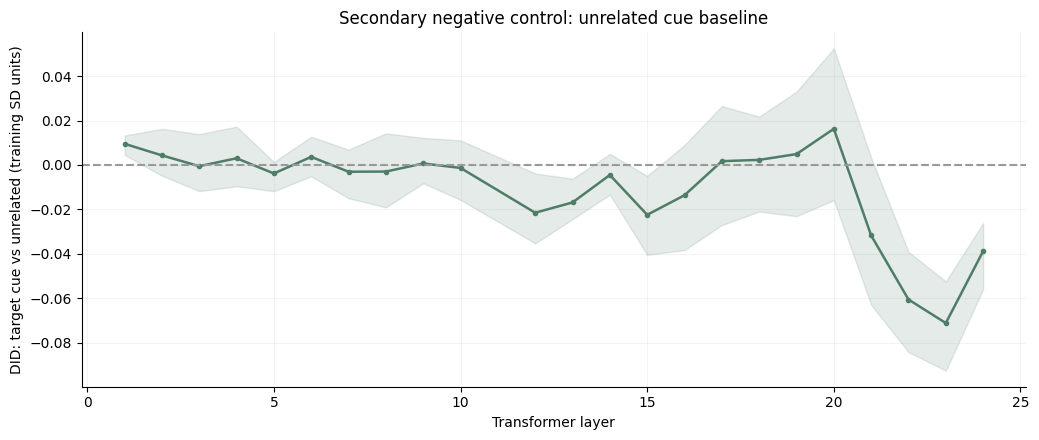

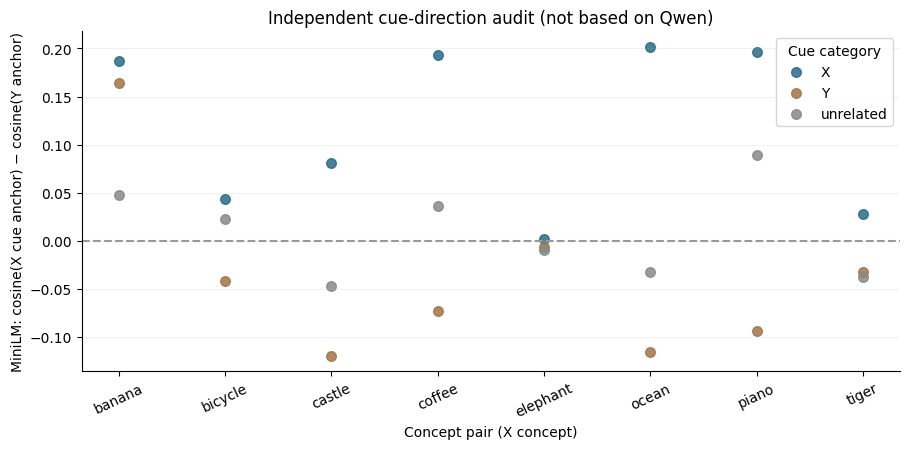

Saved 13_cue_length_balance_by_target_role.csv: 2 rows


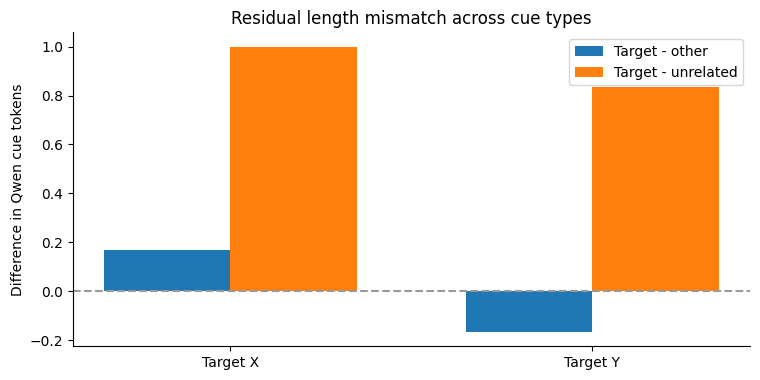

Saved 9 figures, plus complete numerical and validity diagnostics.


In [10]:
# Figure 7: distinction between cue-specific changes and unrelated cue changes
fig,ax=plt.subplots(figsize=(10.5,4.5))
q=summary_df[(summary_df.analysis=="validated")&
             (summary_df.metric=="DID_target_vs_unrelated")&
             (summary_df.n_concept_pairs>=MIN_VALIDATED_FOR_LAYER_PLOT)].sort_values("layer")
if len(q):
    ax.plot(q.layer,q.estimate,"-o",lw=1.8,markersize=3,color="#4F7D67")
    ax.fill_between(q.layer.to_numpy(float),q.ci95_low.to_numpy(float),
        q.ci95_high.to_numpy(float),color="#4F7D67",alpha=.15)
ax.axhline(0,color=".6",ls="--")
ax.set(xlabel="Transformer layer",ylabel="DID: target cue vs unrelated (training SD units)",
       title="Secondary negative control: unrelated cue baseline")
ax.grid(alpha=.14)
save_figure("07_target_vs_unrelated_DID_all_layers.png")

# Figure 8: independent MiniLM lexical/semantic audit, preserving failed cases
fig,ax=plt.subplots(figsize=(9.2,4.6))
cue_avg=cues.groupby(["concept","cue_type"],as_index=False).X_minus_Y_similarity.mean()
for typ,c in [("X","#296B88"),("Y","#A27447"),("unrelated","#888888")]:
    q=cue_avg[cue_avg.cue_type==typ]
    ax.scatter(q.concept,q.X_minus_Y_similarity,color=c,label=typ,s=48,alpha=.85)
ax.axhline(0,color=".6",ls="--")
ax.set(xlabel="Concept pair (X concept)",ylabel="MiniLM: cosine(X cue anchor) − cosine(Y anchor)",
       title="Independent cue-direction audit (not based on Qwen)")
ax.tick_params(axis="x",rotation=25);ax.grid(axis="y",alpha=.16)
ax.legend(title="Cue category")
save_figure("08_independent_semantic_direction_audit.png")

# Figure 9: cue word/token length confounding in matched triplets
tokens=rolewide[rolewide.layer==MAIN_LAYER].groupby("target_role",as_index=False).agg(
    target_other_delta=("target_minus_other_token_count","mean"),
    target_unrelated_delta=("target_minus_unrelated_token_count","mean"))
save_csv(tokens,"13_cue_length_balance_by_target_role.csv")
fig,ax=plt.subplots(figsize=(7.7,3.9))
x=np.arange(len(tokens));width=.35
ax.bar(x-width/2,tokens.target_other_delta,width,label="Target - other")
ax.bar(x+width/2,tokens.target_unrelated_delta,width,label="Target - unrelated")
ax.axhline(0,color=".6",ls="--")
ax.set(xticks=x,xticklabels=["Target "+r for r in tokens.target_role],
       ylabel="Difference in Qwen cue tokens",title="Residual length mismatch across cue types")
ax.legend()
save_figure("09_cue_token_length_balance.png")
print("Saved 9 figures, plus complete numerical and validity diagnostics.")

## 8 — Integrity checks, provenance, and reusable result bundle

Run this cell before interpreting the plots. It checks **all 288 prompts × 24 layers**, identical pre-cue states for identical prefixes, presence of both named-target directions, and balanced three-way cue groups. This code **does not create a success claim** for any research hypothesis; it writes observed results and limitations.

In [11]:
assert len(cues)==72 and len(CONCEPTS)==8
assert len(measure)==8*2*2*3*3*24
assert len(paired)==8*2*3*3*24
assert len(rolewide)==8*2*3*24
assert len(by_role)==8*2*24 and len(by_concept)==8*24
assert len(focus)==8 and focus.n_layers.eq(2).all()
assert set(by_role.target_role)==set(TARGET_ROLES)
assert all(np.isfinite(measure[field]).all() for field in [
 "pre_target_std","post_target_std","delta_target_std",
 "hidden_cosine_distance","hidden_relative_L2"])
assert max(invariance.values())<.01
assert by_concept.groupby("layer").size().eq(8).all()
run_info={
 "title":"1019 v3 X/Y target-specific suppression controls",
 "run_id":RUN_ID,
 "completed_utc":datetime.now(timezone.utc).isoformat(),
 "model":MODEL_ID,"semantic_encoder":EMBED_ID,
 "seed":SEED,"layers":MODEL_LAYERS,
 "focus_layers_chosen_before_v3":[22,23],"comparison_layer":MAIN_LAYER,
 "concept_pairs":CONCEPTS,
 "suppressed_target_roles":["X","Y"],
 "instructions":CONDITIONS,
 "cue_groups":["X","Y","unrelated"],
 "triplets_per_pair":3,
 "total_prompts":8*2*2*3*3,
 "n_probe_readouts_per_layer":8*2*2*3*3*2,
 "measurement_position":"two STATE: tokens in one causally masked forward pass",
 "independent_unit":"concept pair (8), not cue text or target-role reversal",
 "probe_auc_threshold":AUC_CUTOFF,
 "validated_probes_by_layer":{str(int(z.layer)):int(z.n_passed) for z in counts.itertuples()},
 "prespecified_metrics":{
   "primary":"(delta_suppression(target cue)-delta_suppression(other cue)) - (delta_neutral(target cue)-delta_neutral(other cue))",
   "secondary":"(delta_suppression(target cue)-delta_neutral(target cue)) - (delta_suppression(unrelated cue)-delta_neutral(unrelated cue))",
   "normalization":"per concept/layer probe decision scores divided by its training score SD",
   "target_orientation":"sign-flip for Y so positive means toward whichever concept is the named target"},
 "focus_results":main_summary.to_dict(orient="records"),
 "probe_validation_note":"Holdout descriptions are unseen strings but share topic features with training prompts.",
 "embedding_audit":{
  "expected_X_and_Y_direction_n":int(cues[cues.cue_type.isin(["X","Y"])].independent_expected_direction.sum()),
  "total_X_and_Y_cues":int(cues.cue_type.isin(["X","Y"]).sum())},
 "input_pinned_urls":{"stimuli":STIMULI_URL,"descriptions":DESCRIPTION_URL},
 "input_sha256":INPUT_SHA256,
 "pre_cue_state_maximum_difference":float(max(invariance.values())),
 "runtime":{"python":sys.version,"torch":torch.__version__,
            "transformers":__import__("transformers").__version__,
            "device":DEVICE},
 "limitations":[
  "Scores are X-versus-Y decodability, not absolute activation.",
  "Current target appears literally in both instructions; not a test of concept deletion.",
  "Prompt conditions differ in meaning, so observational contrasts do not identify an internal suppression circuit.",
  "Pre and post are distinct token positions, not model-internal elapsed cognitive time.",
  "MiniLM similarity is a separate heuristic model, not human semantic judgments.",
  "Cue descriptions are authored and not statistically representative; only eight concept pairs.",
  "Cue groups are parallel but not perfectly Qwen-token-length-matched.",
  "Held-out description evaluation is small and semantically correlated with training.",
  "Layer 22/23 were selected after exploratory v2 observations; v3 is a follow-up, not independent confirmatory preregistration.",
  "Cluster bootstrap intervals are exploratory, not adjusted for examining all 24 layers.",
  "No causal activation patching or steering is performed."
 ]
}
(OUT/"metadata.json").write_text(json.dumps(run_info,indent=2,ensure_ascii=False),
                                  encoding="utf-8")
readme="\n".join([
 "# 1019 v3 — matched X/Y semantic specificity controls",
 "",
 f"Run: {RUN_ID}",
 f"Model: {MODEL_ID}",
 "",
 "## Main interpretation",
 "Probe measures X-vs-Y decodability, not absolute target activation.",
 "Both X and Y were independently selected as the named forbidden target.",
 "Each cue set includes target-related, comparison-related and unrelated texts.",
 "A positive specificity interaction means suppression increases target-vs-competitor cue discrimination compared with permissive instructions.",
 "A negative specificity interaction means the cue discrimination is weaker under suppression.",
 "Never interpret absolute target state or causal circuit from this alone.",
 "",
 "## Key files",
 "01_audited_XY_control_stimuli.csv — MiniLM sim-to-X/Y and cue length",
 "02_embedding_and_length_audit.csv — matched stimulus quality",
 "03_probe_validation_all_layers.csv — independent holdout AUC",
 "04_probe_validation_flags.csv / 05_probe_validation_per_layer.csv",
 "03_all_layer_target_aligned_pre_post.csv — all prompt-level pre/post readouts",
 "04_precue_causal_invariance.csv — checks causal prefix invariance",
 "05_prompt_and_cue_length_diagnostics.csv — prompt length controls",
 "06_paired_instruction_contrasts.csv — same cue, different instruction",
 "07_triplet_matched_specificity.csv — parallel target vs competitor vs unrelated triples",
 "08_specificity_by_concept_target_layer.csv — target reversal retained",
 "09_specificity_by_concept_layer.csv — unit-of-analysis summaries",
 "10_layerwise_concept_bootstrap.csv — exploratory bootstrap and sign counts",
 "11_prespecified_layers_22_23_by_concept.csv — follow-up focus outcomes",
 "12_prespecified_22_23_bootstrap.csv — focus summary and exploratory CI",
 "13_cue_length_balance_by_target_role.csv — token mismatch diagnostic",
 "01..09_*.png — 9 diagnostic and exploratory plots",
 "metadata.json — exact model, inputs and interpretation limits",
 "",
 "This run does not change any saved v1/v2 result files."
])+"\n"
(OUT/"README.md").write_text(readme,encoding="utf-8")
zip_path=OUT.parent/(RUN_ID+"_results.zip")
with zipfile.ZipFile(zip_path,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUT.iterdir()):
        if path.is_file():z.write(path,arcname=f"1019/results_v3/{RUN_ID}/{path.name}")
print("Experiment finished. CSV:",len(list(OUT.glob("*.csv"))),
      "PNG:",len(list(OUT.glob("*.png"))),
      "JSON:",len(list(OUT.glob("*.json"))))
print("Full result ZIP:",zip_path,"(",round(zip_path.stat().st_size/1024,1),"KiB)")

Experiment finished. CSV: 17 PNG: 9 JSON: 2
Full result ZIP: /content/GraduationThesis/1019/results_v3/20261020T070234997011Z_results.zip ( 1676.9 KiB)


## 9 — Optional secure upload to GitHub

Set **Colab Secrets → `GITHUB_RESULTS_TOKEN`**, grant notebook access, and ensure the token has **Contents: Read and write** access to `ryouy/GraduationThesis`. The notebook will upload all CSV, PNG, JSON and README files into a **new timestamped `1019/results_v3/<run-id>/` folder**. If no token is supplied, the local results remain valid and the ZIP can be downloaded. Tokens are never saved to the repository or exported files.

In [12]:
def get_results_token():
    try:
        from google.colab import userdata
        return userdata.get("GITHUB_RESULTS_TOKEN")
    except Exception:
        return os.environ.get("GITHUB_RESULTS_TOKEN")
if UPLOAD_TO_GITHUB:
    secret=get_results_token()
    if not secret:
        print("Skipping GitHub upload: Colab Secret GITHUB_RESULTS_TOKEN unavailable.")
        print("All outputs are available locally:",OUT)
    else:
        headers={"Authorization":"Bearer "+secret,
                 "Accept":"application/vnd.github+json",
                 "X-GitHub-Api-Version":"2022-11-28"}
        outputs=[p for p in sorted(OUT.iterdir()) if p.is_file() and
                 p.suffix.lower() in {".csv",".png",".json",".md"}]
        success=[];fail=[]
        for file in tqdm(outputs,desc="Upload v3 outputs to GitHub"):
            remote=f"1019/results_v3/{RUN_ID}/{file.name}"
            url=f"https://api.github.com/repos/{REPO}/contents/{remote}"
            payload={"message":f"research: store v3 specificity run {RUN_ID}: {file.name}",
                     "content":base64.b64encode(file.read_bytes()).decode("ascii"),
                     "branch":BRANCH}
            try:
                check=requests.get(url,headers=headers,timeout=30)
                if check.status_code==200:
                    payload["sha"]=check.json()["sha"]
                elif check.status_code!=404:
                    raise RuntimeError("Preflight HTTP "+str(check.status_code))
                res=requests.put(url,headers=headers,json=payload,timeout=90)
                if res.status_code not in (200,201):
                    raise RuntimeError("Upload HTTP "+str(res.status_code)+
                        " (check repository Contents write permission)")
                success.append(remote)
            except Exception as exc:
                fail.append((remote,str(exc)))
                print("WARNING:",file.name,str(exc))
        print(f"Uploaded {len(success)}/{len(outputs)} files.")
        if success:print(f"https://github.com/{REPO}/tree/{BRANCH}/1019/results_v3/{RUN_ID}")
        if fail:print("Partial upload; retry this cell or use the local ZIP.")
        del secret,headers
else:
    print("Upload disabled. Local results at",OUT)

Skipping GitHub upload: Colab Secret GITHUB_RESULTS_TOKEN unavailable.
All outputs are available locally: /content/GraduationThesis/1019/results_v3/20261020T070234997011Z


In [13]:
# Optional: download full local CSV, PNG, JSON and README archive.
try:
    from google.colab import files as colab_files
    colab_files.download(str(zip_path))
except ImportError:
    print("Archive:",zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>